In [1]:
import pandas as pd, numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

target = "SeriousDlqin2yrs"
tr = pd.read_csv("../data/clean/train_clean.csv")
va = pd.read_csv("../data/clean/val_clean.csv")

X_tr, y_tr = tr.drop(columns=target), tr[target]
X_va, y_va = va.drop(columns=target), va[target]

logit = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
logit.fit(X_tr, y_tr)

def report(name, y, p):
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    print(f"{name}: AUC={auc:.4f}  Gini={2*auc-1:.4f}  KS={np.max(tpr-fpr):.4f}")

report("Train", y_tr, logit.predict_proba(X_tr)[:, 1])
report("Val  ", y_va, logit.predict_proba(X_va)[:, 1])

Train: AUC=0.8563  Gini=0.7126  KS=0.5510
Val  : AUC=0.8605  Gini=0.7209  KS=0.5653


XBOOST




In [2]:
import os, joblib
from xgboost import XGBClassifier

os.makedirs("../models", exist_ok=True)
joblib.dump(logit, "../models/logit.joblib")

spw = (y_tr == 0).sum() / (y_tr == 1).sum()

xgb = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric="auc",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

print("Jumlah pohon terbaik:", xgb.best_iteration)
report("Train", y_tr, xgb.predict_proba(X_tr)[:, 1])
report("Val  ", y_va, xgb.predict_proba(X_va)[:, 1])

joblib.dump(xgb, "../models/xgb.joblib")

Jumlah pohon terbaik: 433
Train: AUC=0.8795  Gini=0.7589  KS=0.5974
Val  : AUC=0.8703  Gini=0.7406  KS=0.5838


['../models/xgb.joblib']

Default rate aktual di val: 0.0668
Logit: rata-rata PD mentah=0.3375 | setelah kalibrasi=0.0668
XGB  : rata-rata PD mentah=0.3160 | setelah kalibrasi=0.0668

Logit setelah kalibrasi: AUC=0.8626  Gini=0.7251  KS=0.5653
XGB setelah kalibrasi  : AUC=0.8719  Gini=0.7438  KS=0.5838


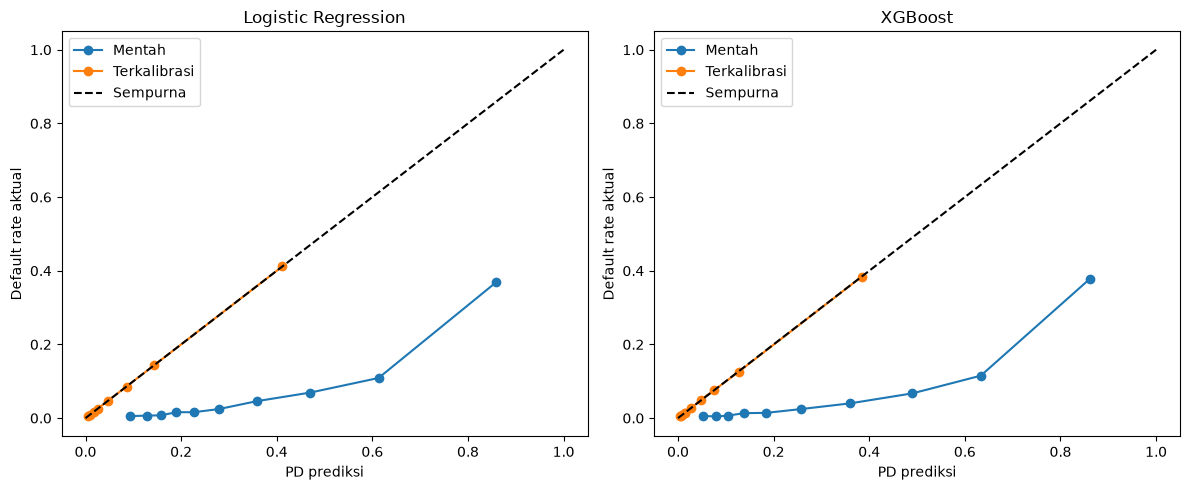

['../models/iso_xgb.joblib']

In [3]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

p_logit_va = logit.predict_proba(X_va)[:, 1]
p_xgb_va = xgb.predict_proba(X_va)[:, 1]

iso_logit = IsotonicRegression(out_of_bounds="clip").fit(p_logit_va, y_va)
iso_xgb = IsotonicRegression(out_of_bounds="clip").fit(p_xgb_va, y_va)

cal_logit_va = iso_logit.predict(p_logit_va)
cal_xgb_va = iso_xgb.predict(p_xgb_va)

print("Default rate aktual di val:", round(y_va.mean(), 4))
for name, raw, cal in [("Logit", p_logit_va, cal_logit_va), ("XGB  ", p_xgb_va, cal_xgb_va)]:
    print(f"{name}: rata-rata PD mentah={raw.mean():.4f} | setelah kalibrasi={cal.mean():.4f}")

print()
report("Logit setelah kalibrasi", y_va, cal_logit_va)
report("XGB setelah kalibrasi  ", y_va, cal_xgb_va)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, raw, cal in [(axes[0], "Logistic Regression", p_logit_va, cal_logit_va),
                           (axes[1], "XGBoost", p_xgb_va, cal_xgb_va)]:
    for label, p in [("Mentah", raw), ("Terkalibrasi", cal)]:
        frac, mean_p = calibration_curve(y_va, p, n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", label=label)
    ax.plot([0, 1], [0, 1], "k--", label="Sempurna")
    ax.set_title(name)
    ax.set_xlabel("PD prediksi")
    ax.set_ylabel("Default rate aktual")
    ax.legend()
plt.tight_layout()
plt.savefig("../reports/calibration_val.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(iso_logit, "../models/iso_logit.joblib")
joblib.dump(iso_xgb, "../models/iso_xgb.joblib")

Logit
  rasio 3:1 -> cutoff=0.182 | precision=0.412 recall=0.505 | biaya=3,319 vs setujui semua=4,512 (hemat 26.4%)
  rasio 5:1 -> cutoff=0.140 | precision=0.366 recall=0.559 | biaya=4,772 vs setujui semua=7,520 (hemat 36.5%)
  rasio 10:1 -> cutoff=0.081 | precision=0.235 recall=0.731 | biaya=7,619 vs setujui semua=15,040 (hemat 49.3%)

XGB
  rasio 3:1 -> cutoff=0.247 | precision=0.467 recall=0.439 | biaya=3,283 vs setujui semua=4,512 (hemat 27.2%)
  rasio 5:1 -> cutoff=0.158 | precision=0.363 recall=0.593 | biaya=4,624 vs setujui semua=7,520 (hemat 38.5%)
  rasio 10:1 -> cutoff=0.071 | precision=0.240 recall=0.755 | biaya=7,293 vs setujui semua=15,040 (hemat 51.5%)



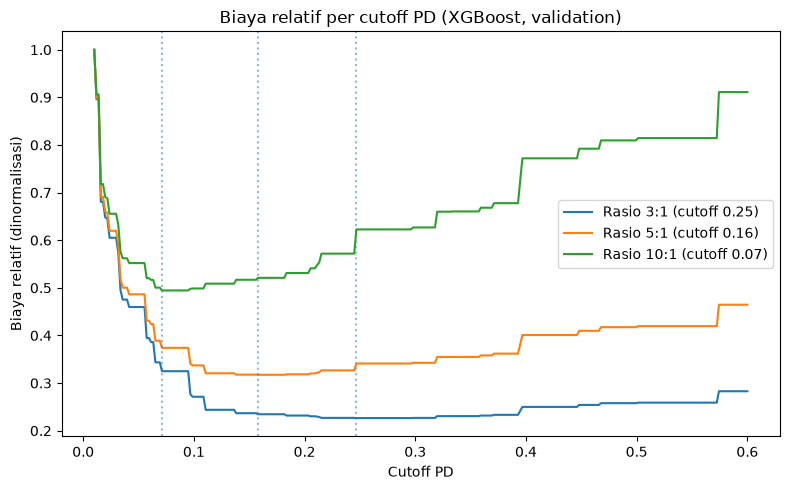

In [4]:
from sklearn.metrics import precision_score, recall_score

y = y_va.values
thresholds = np.linspace(0.01, 0.60, 300)
ratios = [3, 5, 10]

def cost_curve(p, ratio):
    out = []
    for t in thresholds:
        pred = p >= t
        fn = ((~pred) & (y == 1)).sum()
        fp = (pred & (y == 0)).sum()
        out.append(ratio * fn + fp)
    return np.array(out)

models = {"Logit": cal_logit_va, "XGB": cal_xgb_va}

for name, p in models.items():
    print(name)
    for r in ratios:
        c = cost_curve(p, r)
        best_t = thresholds[c.argmin()]
        pred = p >= best_t
        approve_all = r * (y == 1).sum()
        print(f"  rasio {r}:1 -> cutoff={best_t:.3f} | "
              f"precision={precision_score(y, pred):.3f} recall={recall_score(y, pred):.3f} | "
              f"biaya={c.min():,.0f} vs setujui semua={approve_all:,.0f} "
              f"(hemat {1 - c.min()/approve_all:.1%})")
    print()

fig, ax = plt.subplots(figsize=(8, 5))
for r in ratios:
    c = cost_curve(models["XGB"], r)
    ax.plot(thresholds, c / c.max(), label=f"Rasio {r}:1 (cutoff {thresholds[c.argmin()]:.2f})")
    ax.axvline(thresholds[c.argmin()], linestyle=":", alpha=0.5)
ax.set_title("Biaya relatif per cutoff PD (XGBoost, validation)")
ax.set_xlabel("Cutoff PD")
ax.set_ylabel("Biaya relatif (dinormalisasi)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/cutoff_cost.png", dpi=150, bbox_inches="tight")
plt.show()